# willmarley: pick a motor, prop and battery

Tracks [issue #85](https://github.com/MarMar888/hav/issues/85).

Every input has a low/high bound. The notebook searches inside those bounds for the fastest boat
that still passes the checks, prints that design, then runs the SSS motor catalog through the same
search so you know what to buy.

How it hangs together: the battery gives volts and amps, the motor turns them into rpm and torque,
the prop turns that into push, the water pushes back harder the heavier and faster the boat is.
Speed is where push and push-back balance. The battery's own weight is in the loop.

In [1]:
import csv
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

RHO = 999.0          # water density, kg/m^3
M_PER_IN = 0.0254
N_PER_LBF = 4.4482
MPS_PER_MPH = 0.44704
G_PER_LB = 453.592
PITCH_UNITS = 1056   # in/min per mph

BLUE, DARK, GRAY = "#4292c6", "#08519c", "#d8d6cf"

## 1. Inputs

Decision variables and their bounds. Edit here and re-run everything.

In [2]:
BOUNDS = {
    # motor
    "Kv":       (300.0, 1200.0),   # rpm per volt
    "R":        (0.005, 0.050),    # winding resistance, ohm
    "I0":       (1.0, 6.0),        # no-load current, A
    "I_max":    (50.0, 320.0),     # current limit, A
    "W_motor":  (0.4, 5.0),        # lb each
    "n_motors": (1, 2),
    # prop
    "K_Q":      (0.02, 0.05),      # torque coefficient
    "K_T":      (0.05, 0.15),      # thrust coefficient
    "D_in":     (2.0, 7.0),        # diameter, in
    "eta_p":    (0.5, 0.7),        # prop efficiency
    # battery
    "V":        (20.0, 50.0),      # pack voltage
    "e_batt":   (50.0, 100.0),     # Wh per lb
    # hull
    "W_hull":   (30.0, 90.0),      # bare hull, lb
    "LD0":      (5.0, 10.0),       # peak lift-to-drag
}
UNITS = {"Kv": "rpm/V", "R": "ohm", "I0": "A", "I_max": "A", "W_motor": "lb", "n_motors": "-",
         "K_Q": "-", "K_T": "-", "D_in": "in", "eta_p": "-", "V": "V", "e_batt": "Wh/lb",
         "W_hull": "lb", "LD0": "-"}
MOTOR_KEYS = ["Kv", "R", "I0", "I_max", "W_motor"]
NON_MOTOR = [k for k in BOUNDS if k not in MOTOR_KEYS]

# Fixed, not searched
RACE = {"miles": 5.0, "reserve": 1.3}  # EDIT to the real course
USABLE = 0.8              # discharge depth
DISCHARGE_DERATE = 0.8    # steady draw at 80% of pack rating
C_RATE_MAX = 10.0         # hottest pack we'd buy
SLIP_TARGET = 0.80        # prop runs at 80% of pitch speed
PITCH_BUYABLE = (6.0, 14.0)
V_LD_HALF = 26.0          # mph where friction has doubled the drag
W_FIXED_LB = 30.0 + 5.0   # payload + safety margin, lb

# What a design has to pass
REQS = {"min_speed_mph": 15.0, "max_weight_lb": 160.0, "min_motor_eff": 0.5}

print(f"{'input':<9}{'low':>8}{'high':>8}  unit")
for k, (lo, hi) in BOUNDS.items():
    print(f"{k:<9}{lo:>8g}{hi:>8g}  {UNITS[k]}")
print(f"\nrace: {RACE['miles']:g} mi, +{RACE['reserve'] - 1:.0%} reserve.  payload + margin: {W_FIXED_LB:g} lb")

input         low    high  unit
Kv            300    1200  rpm/V
R           0.005    0.05  ohm
I0              1       6  A
I_max          50     320  A
W_motor       0.4       5  lb
n_motors        1       2  -
K_Q          0.02    0.05  -
K_T          0.05    0.15  -
D_in            2       7  in
eta_p         0.5     0.7  -
V              20      50  V
e_batt         50     100  Wh/lb
W_hull         30      90  lb
LD0             5      10  -

race: 5 mi, +30% reserve.  payload + margin: 35 lb


## 2. The model

```text
motor    Kt  = 60 / (2π·Kv)                 torque per amp
         Q   = Kt·(I − I0)                  torque out
         rpm = Kv·(V − I·R)                 I ≤ I_max
prop     Q   = K_Q·ρ·n²·D⁵                  torque the prop demands (n in rev/s)
         T   = K_T·ρ·n²·D⁴                  most thrust it can give
         pitch = speed·1056 / (rpm·0.8)     pitch to buy
battery  C   = I·(course/speed)·reserve/0.8   Ah the race needs
         W_batt = C·V / e_batt              lb
         C_rate = I / (0.8·C)               rating the pack must carry
hull     W   = W_hull + W_batt + n·W_motor + 35
         L/D = LD0 / (1 + (v/26)²)
         drag = W / L/D                     lbf
speed    η_p·P_shaft = drag·speed           solve for speed
```

The solve: motor torque = prop torque gives rpm and amps. Shaft power and drag give speed. The race
sizes the pack, the pack adds weight, weight slows the boat, so it loops until it settles.

Checks a design has to pass: speed ≥ 15 mph, weight ≤ 160 lb, motor efficiency ≥ 0.5, prop thrust
covers drag, C-rate ≤ 10, pitch between 6 and 14 in.

In [3]:
def cbrt(x):
    return math.copysign(abs(x) ** (1 / 3), x)


def motor_prop_balance(Kv, R, I0, I_max, V, K_Q, D_in):
    """rpm, amps, torque where one motor's torque equals the prop's demand."""
    Kt = 60 / (2 * math.pi * Kv)
    prop_load = K_Q * RHO * (D_in * M_PER_IN) ** 5     # prop torque = prop_load * (rpm/60)^2
    a, b, c = prop_load / 3600, Kt / (Kv * R), Kt * (V / R - I0)
    rpm = (-b + math.sqrt(b * b + 4 * a * c)) / (2 * a)
    amps = (V - rpm / Kv) / R
    limited = amps > I_max
    if limited:
        amps = I_max
        rpm = 60 * math.sqrt(Kt * (amps - I0) / prop_load)
    return rpm, amps, Kt * (amps - I0), limited


def speed_from_power(shaft_w, eta_p, W, LD0):
    """mph where pull power = drag * speed. Cubic with one real root."""
    watts_per_mph = (W * N_PER_LBF / LD0) * MPS_PER_MPH
    q = eta_p * shaft_w * V_LD_HALF ** 2 / watts_per_mph
    s = math.sqrt(q * q / 4 + V_LD_HALF ** 6 / 27)
    return cbrt(q / 2 + s) + cbrt(q / 2 - s)


def solve(Kv, R, I0, I_max, W_motor, n_motors, K_Q, K_T, D_in, eta_p, V, e_batt, W_hull, LD0):
    rpm, amps_1, torque, limited = motor_prop_balance(Kv, R, I0, I_max, V, K_Q, D_in)
    shaft_w = n_motors * torque * 2 * math.pi * rpm / 60
    amps = n_motors * amps_1

    C = 50.0
    for _ in range(25):                     # pack size <-> weight <-> speed loop
        W = W_hull + C * V / e_batt + n_motors * W_motor + W_FIXED_LB
        mph = speed_from_power(shaft_w, eta_p, W, LD0)
        C_new = min(amps * RACE["miles"] / max(mph, 2.0) * RACE["reserve"] / USABLE, 400.0)
        done = abs(C_new - C) < 0.05
        C = C_new
        if done:
            break

    W_batt = C * V / e_batt
    W = W_hull + W_batt + n_motors * W_motor + W_FIXED_LB
    LD = LD0 / (1 + (mph / V_LD_HALF) ** 2)
    thrust = n_motors * K_T * RHO * (rpm / 60) ** 2 * (D_in * M_PER_IN) ** 4 / N_PER_LBF
    return dict(mph=mph, rpm=rpm, amps=amps, amps_1=amps_1, torque=torque, limited=limited,
                shaft_w=shaft_w, eff=shaft_w / (V * amps), V_needed=rpm / Kv + amps_1 * R,
                C=C, W_batt=W_batt, W=W, c_rate=amps / (DISCHARGE_DERATE * C),
                pitch=mph * PITCH_UNITS / (rpm * SLIP_TARGET),
                drag=W / LD, thrust=thrust, minutes=60 * USABLE * C / amps)


def ok(r):
    return (r["mph"] >= REQS["min_speed_mph"] and r["W"] <= REQS["max_weight_lb"]
            and r["eff"] >= REQS["min_motor_eff"] and r["thrust"] >= r["drag"]
            and r["c_rate"] <= C_RATE_MAX and PITCH_BUYABLE[0] <= r["pitch"] <= PITCH_BUYABLE[1])

### How it connects

Inputs on the left, the calculation steps in the middle (named after the functions above), outputs
on the right. `V` does two jobs: it sets rpm and it sets pack weight. Speed feeds back into pack
size, which is the loop in `solve()`.

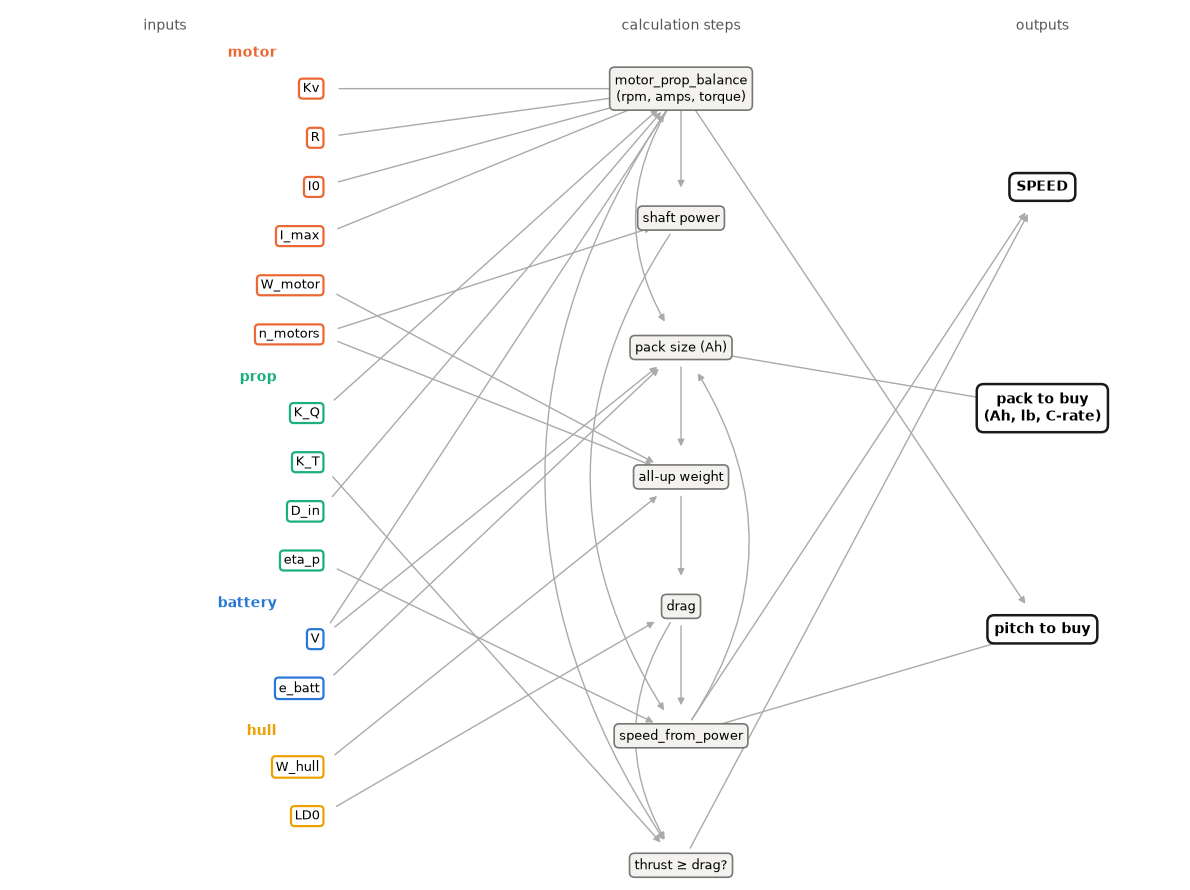

In [4]:
GROUPS = {"motor": ("#eb6834", MOTOR_KEYS + ["n_motors"]), "prop": ("#1baf7a", ["K_Q", "K_T", "D_in", "eta_p"]),
          "battery": ("#2a78d6", ["V", "e_batt"]), "hull": ("#eda100", ["W_hull", "LD0"])}
STEPS = ["motor_prop_balance\n(rpm, amps, torque)", "shaft power", "pack size (Ah)", "all-up weight",
         "drag", "speed_from_power", "thrust ≥ drag?"]
OUTS = ["SPEED", "pack to buy\n(Ah, lb, C-rate)", "pitch to buy"]
B, P, W, D, S, T = STEPS[0], STEPS[2], STEPS[3], STEPS[4], STEPS[5], STEPS[6]
EDGES = [("Kv", B), ("R", B), ("I0", B), ("I_max", B), ("V", B), ("K_Q", B), ("D_in", B),
         (B, "shaft power"), ("n_motors", "shaft power"),
         (B, P), (S, P), ("V", P), ("e_batt", P),
         (P, W), ("W_hull", W), ("W_motor", W), ("n_motors", W),
         (W, D), ("LD0", D),
         ("shaft power", S), ("eta_p", S), (D, S),
         ("K_T", T), (B, T), (D, T),
         (S, "SPEED"), (T, "SPEED"), (P, OUTS[1]), (S, "pitch to buy"), (B, "pitch to buy")]

pos, y = {}, 0.0
for name, (color, keys) in GROUPS.items():
    for k in keys:
        pos[k] = (0, y); y -= 1
    y -= 0.6
for i, name in enumerate(STEPS):
    pos[name] = (2.1, i * (y + 0.6) / (len(STEPS) - 1))   # spread down the same height as the inputs
for i, name in enumerate(OUTS):
    pos[name] = (4.2, -2 - i * 4.5)

fig, ax = plt.subplots(figsize=(12, 9))
for a, b in EDGES:
    hop = abs(STEPS.index(a) - STEPS.index(b)) if a in STEPS and b in STEPS else 0
    rad = 0.35 if hop > 1 else 0.0         # long hops in the middle column bow around the nodes between
    ax.annotate("", xy=pos[b], xytext=pos[a], arrowprops=dict(arrowstyle="-|>", color="#aaaaaa", lw=1,
                shrinkA=14, shrinkB=22, connectionstyle=f"arc3,rad={rad}"))
for name, (color, keys) in GROUPS.items():
    ax.text(-0.25, pos[keys[0]][1] + 0.65, name, color=color, fontsize=10, fontweight="bold", ha="right")
    for k in keys:
        ax.text(*pos[k], k, ha="right", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, lw=1.6))
for name in STEPS:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f3f2ee", ec="#777777", lw=1.2))
for name in OUTS:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#1a1a19", lw=1.8))
ax.text(-0.9, 1.2, "inputs", ha="center", fontsize=10, color="#555555")
ax.text(2.1, 1.2, "calculation steps", ha="center", fontsize=10, color="#555555")
ax.text(4.2, 1.2, "outputs", ha="center", fontsize=10, color="#555555")
ax.set_xlim(-1.8, 5.0); ax.set_ylim(y + 0.3, 1.6); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Fastest design inside the bounds

Random search over every bound (20,000 tries), keep the fastest that passes, then nudge each input
up and down until it stops getting faster.

One thing to know: because the pack is sized to the race, its C-rate is just
`speed / (miles × reserve)`. So the 10C pack cap is really a speed cap: 10 × 5 × 1.3 = 65 mph. Any
design that hits 65 is sitting on that cap. Raise `C_RATE_MAX` (hotter pack) or shorten the reserve
to go faster.

In [5]:
def random_designs(bounds, n, rng, fixed=None):
    """n random designs inside bounds. fixed = inputs held at one value (e.g. a catalog motor)."""
    fixed = fixed or {}
    d = {k: rng.uniform(lo, hi, n) for k, (lo, hi) in bounds.items() if k not in fixed}
    if "n_motors" in d:
        d["n_motors"] = rng.integers(1, 3, n).astype(float)
    if "V" in d and "v_max" in fixed:
        d["V"] = np.minimum(d["V"], fixed["v_max"])    # only buy a pack the motor can take
    return [{**{k: d[k][i] for k in d}, **{k: fixed[k] for k in bounds if k in fixed}} for i in range(n)]


def fastest(bounds, n=20000, seed=0, fixed=None, max_rpm=None):
    """Best passing design: random search, then hill-climb on the continuous inputs."""
    rng = np.random.default_rng(seed)
    free = [k for k in bounds if k != "n_motors" and k not in (fixed or {})]

    def score(x):
        r = solve(**x)
        return r["mph"] if ok(r) and (max_rpm is None or r["rpm"] <= max_rpm) else -1.0

    designs = random_designs(bounds, n, rng, fixed)
    scores = [score(x) for x in designs]
    if max(scores) < 0:
        return None, None, designs, scores
    best = dict(designs[int(np.argmax(scores))])
    best_s = max(scores)
    step = 0.05
    while step > 0.001:
        improved = False
        for k in free:
            lo, hi = bounds[k]
            for sign in (+1, -1):
                trial = {**best, k: float(np.clip(best[k] + sign * step * (hi - lo), lo, hi))}
                s = score(trial)
                if s > best_s:
                    best, best_s, improved = trial, s, True
        if not improved:
            step /= 2
    return best, solve(**best), designs, scores


BEST, R_BEST, SAMPLES, SAMPLE_MPH = fastest(BOUNDS)
n_pass = sum(s > 0 for s in SAMPLE_MPH)
SPEED_CAP = C_RATE_MAX * RACE["miles"] * RACE["reserve"]
print(f"{n_pass} of {len(SAMPLES)} random designs pass the checks; fastest after tuning: {R_BEST['mph']:.1f} mph")
print(f"(speed cap from the {C_RATE_MAX:g}C pack limit: {SPEED_CAP:.0f} mph)\n")

print(f"{'input':<9}{'value':>9}{'low':>8}{'high':>8}  note")
for k, (lo, hi) in BOUNDS.items():
    x = BEST[k]
    at = "AT LOW BOUND" if x <= lo + 0.02 * (hi - lo) else "AT HIGH BOUND" if x >= hi - 0.02 * (hi - lo) else ""
    print(f"{k:<9}{x:>9.4g}{lo:>8g}{hi:>8g}  {at}")
print("(an input at a bound means the bound is choosing, not the physics: widen it if it was a guess)")


def show(r, V=None):
    print(f"""
rpm                 {r['rpm']:8.0f}
amps per motor      {r['amps_1']:8.0f}      (at the motor's limit: {'yes' if r['limited'] else 'no'})
torque per motor    {r['torque']:8.2f} N·m
shaft power         {r['shaft_w'] / 1000:8.1f} kW total
motor efficiency    {r['eff']:8.2f}
volts needed        {r['V_needed']:8.1f} V
pack to buy         {r['C']:8.0f} Ah,  {r['W_batt']:.0f} lb,  {r['c_rate']:.1f}C rating
all-up weight       {r['W']:8.0f} lb
pitch to buy        {r['pitch']:8.1f} in
thrust vs drag      {r['thrust']:8.0f} vs {r['drag']:.0f} lbf
SPEED               {r['mph']:8.1f} mph   race {60 * RACE['miles'] / r['mph']:.1f} min""")


show(R_BEST)

154 of 20000 random designs pass the checks; fastest after tuning: 65.0 mph
(speed cap from the 10C pack limit: 65 mph)

input        value     low    high  note
Kv           314.9     300    1200  AT LOW BOUND
R          0.02396   0.005    0.05  
I0               1       1       6  AT LOW BOUND
I_max          320      50     320  AT HIGH BOUND
W_motor      2.674     0.4       5  
n_motors         2       1       2  AT HIGH BOUND
K_Q        0.04753    0.02    0.05  
K_T         0.1414    0.05    0.15  
D_in         3.715       2       7  
eta_p       0.5733     0.5     0.7  
V            45.98      20      50  
e_batt         100      50     100  AT HIGH BOUND
W_hull       43.87      30      90  
LD0          9.853       5      10  
(an input at a bound means the bound is choosing, not the physics: widen it if it was a guess)

rpm                     9904
amps per motor           320      (at the motor's limit: yes)
torque per motor        9.67 N·m
shaft power             20.1 kW total

## 4. What each input does

Sweep one input across its bounds with every other input held at the best design. Orange = motor
at its current limit. Gray band = fails a check.

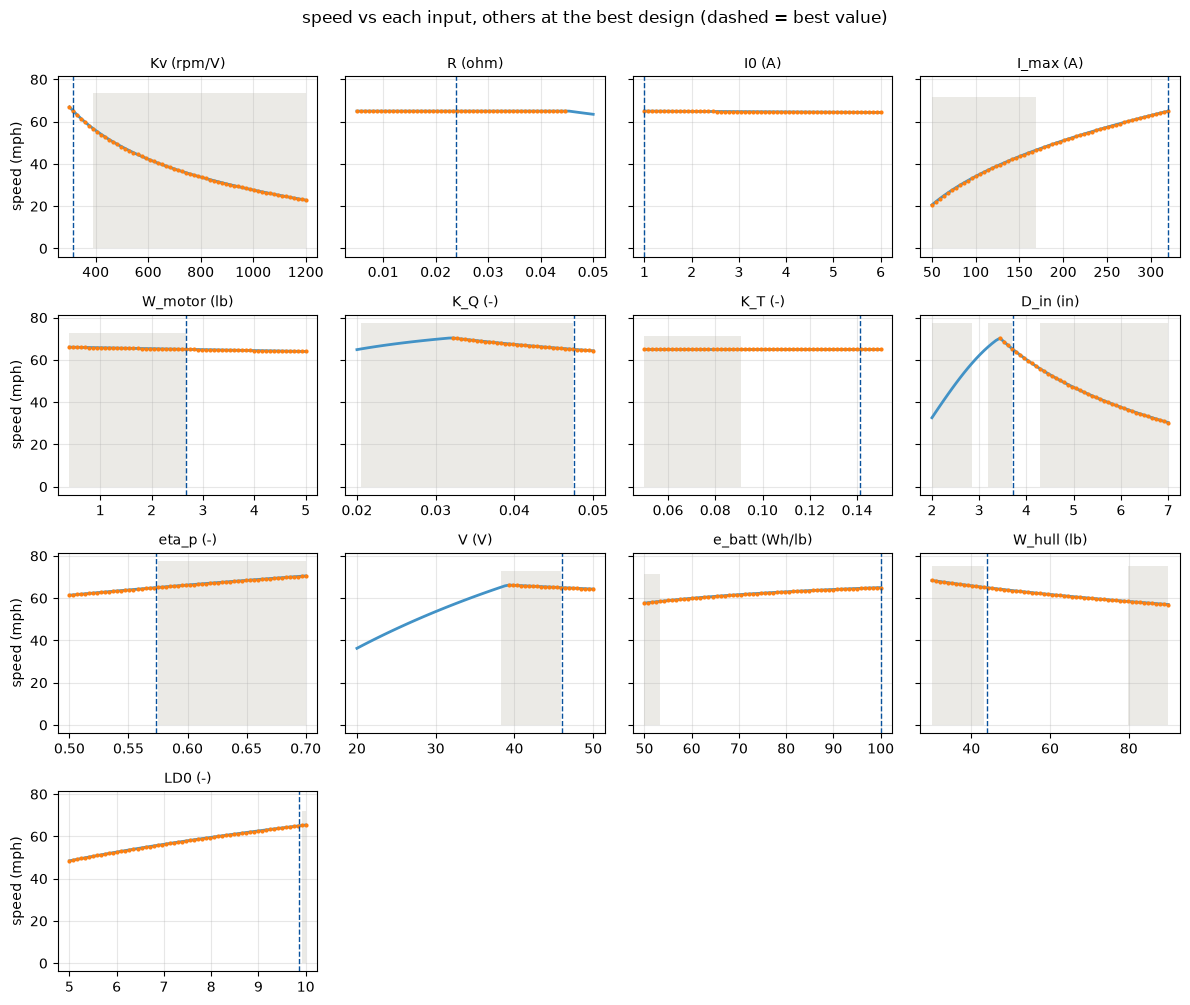

In [6]:
keys = [k for k in BOUNDS if k != "n_motors"]
fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharey=True)
for k, ax in zip(keys, axes.flat):
    lo, hi = BOUNDS[k]
    xs = np.linspace(lo, hi, 60)
    rs = [solve(**{**BEST, k: x}) for x in xs]
    mph = np.array([r["mph"] for r in rs])
    bad = np.array([not ok(r) for r in rs])
    lim = np.array([r["limited"] for r in rs])
    ax.plot(xs, mph, color=BLUE, lw=2)
    ax.plot(xs[lim], mph[lim], ".", color="tab:orange", ms=4)
    ax.fill_between(xs, 0, mph.max() * 1.1, where=bad, color=GRAY, alpha=0.5, lw=0)
    ax.axvline(BEST[k], color=DARK, lw=1, ls="--")
    ax.set_title(f"{k} ({UNITS[k]})", fontsize=10); ax.grid(alpha=0.3)
for ax in axes.flat[len(keys):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("speed (mph)")
fig.suptitle("speed vs each input, others at the best design (dashed = best value)", y=1.0)
plt.tight_layout(); plt.show()

## 5. The SSS catalog

Same search, but the motor comes off the supplier sheet (`sss_motors.csv`) instead of the bounds.
Pack voltage is capped at the winding's `v_max`, and spinning past `max_rpm` fails. Sorted by the
fastest design each winding can reach; ties (everything on the 65 mph cap) go to the more forgiving
winding, the one that works with more random prop/battery/hull combos.

In [7]:
with open("sss_motors.csv") as f:
    CATALOG = [dict(name=f"{r['motor']} {r['winding']}", Kv=float(r["kv_rpm_per_v"]), R=float(r["r_ohm"]),
                    I0=float(r["i0_a_at_11v"]), I_max=float(r["i_max_a"]), W_motor=float(r["weight_g"]) / G_PER_LB,
                    v_max=float(r["v_max_v"]), max_rpm=float(r["max_rpm"]))
               for r in csv.DictReader(f)]

results = []
for m in CATALOG:
    best, r, designs, scores = fastest(BOUNDS, n=2000, seed=1, fixed=m, max_rpm=m["max_rpm"])
    results.append(dict(m=m, best=best, r=r, pass_frac=np.mean([s > 0 for s in scores])))
results.sort(key=lambda x: (-round(x["r"]["mph"] if x["r"] else 0, 1), -x["pass_frac"]))  # fastest, then most forgiving

n_none = sum(1 for x in results if x["r"] is None)
print(f"{len(CATALOG)} windings on the sheet, {n_none} can't make a passing design\n")
print(f"{'winding':<22}{'Kv':>6}{'v_max':>7}{'I_max':>7}{'best mph':>10}{'passes':>9}")
for x in results[:12]:
    m = x["m"]
    print(f"{m['name']:<22}{m['Kv']:>6.0f}{m['v_max']:>7.0f}{m['I_max']:>7.0f}{x['r']['mph']:>10.1f}{x['pass_frac']:>9.1%}")
print("\n(passes = share of random prop/battery/hull combos that work with this winding: a forgiving motor scores high)")

263 windings on the sheet, 207 can't make a passing design

winding                   Kv  v_max  I_max  best mph   passes
SSS 56154-V2 10Y         200    125    160      65.0    18.9%
SSS 56154-V2 9Y          220    112    178      65.0    16.7%
SSS 56154-V2 8Y          250     99    202      65.0    14.2%
SSS 56154-V2 7Y          280     88    227      65.0    12.0%
SSS 56154-V2 6Y          330     75    266      65.0     8.4%
SSS 56154-V2 5Y          400     62    320      65.0     5.0%
SSS 56133-V2 7Y          350    103    168      65.0     3.6%
SSS 56133-V2 6Y          400     85    208      65.0     2.9%
SSS 56154-V2 4Y          500     50    400      65.0     2.2%
SSS 56133-V2 5Y          500     72    248      65.0     1.2%
SSS 56154-V2 3Y          650     38    525      65.0     0.7%
SSS 56154-V2 11Y         180    138    145      64.5    20.8%

(passes = share of random prop/battery/hull combos that work with this winding: a forgiving motor scores high)


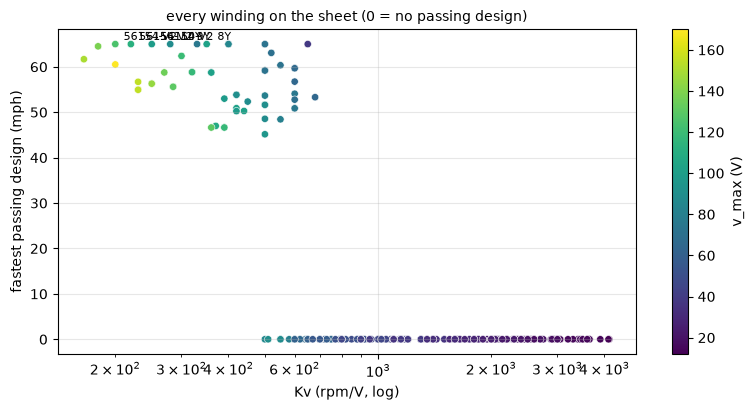

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
kv = [x["m"]["Kv"] for x in results]
mph = [x["r"]["mph"] if x["r"] else 0 for x in results]
vmax = [x["m"]["v_max"] for x in results]
sc = ax.scatter(kv, mph, c=vmax, cmap="viridis", s=28, edgecolors="white", linewidths=0.4)
for x in results[:3]:
    ax.annotate(x["m"]["name"].replace("SSS ", ""), (x["m"]["Kv"], x["r"]["mph"]),
                xytext=(6, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Kv (rpm/V, log)"); ax.set_ylabel("fastest passing design (mph)")
ax.set_title("every winding on the sheet (0 = no passing design)", fontsize=10); ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label="v_max (V)")
plt.tight_layout(); plt.show()

## 6. Shopping list

The three best windings and the design each one wants.

In [9]:
PICKS = results[:3]
W = 30


def row(label, vals):
    print(f"{label:<{W}}" + "".join(f"{v:>18}" for v in vals))


row("", [x["m"]["name"].replace("SSS ", "") for x in PICKS])
print("-" * (W + 18 * len(PICKS)))
row("motors", [f"{x['best']['n_motors']:.0f}" for x in PICKS])
row("Kv (rpm/V)", [f"{x['m']['Kv']:g}" for x in PICKS])
row("I_max (A)", [f"{x['m']['I_max']:g}" for x in PICKS])
row("winding v_max (V)", [f"{x['m']['v_max']:g}" for x in PICKS])
print()
row("prop diameter (in)", [f"{x['best']['D_in']:.1f}" for x in PICKS])
row("prop pitch to buy (in)", [f"{x['r']['pitch']:.1f}" for x in PICKS])
for k in ("K_Q", "K_T", "eta_p"):
    row(f"prop {k}", [f"{x['best'][k]:.3g}" for x in PICKS])
print()
row("pack voltage (V)", [f"{x['best']['V']:.0f}" for x in PICKS])
row("volts needed (V)", [f"{x['r']['V_needed']:.1f}" for x in PICKS])
row("pack to buy (Ah)", [f"{x['r']['C']:.0f}" for x in PICKS])
row("pack weight (lb)", [f"{x['r']['W_batt']:.0f}" for x in PICKS])
row("pack rating needed", [f"{x['r']['c_rate']:.1f}C" for x in PICKS])
row("e_batt (Wh/lb)", [f"{x['best']['e_batt']:.0f}" for x in PICKS])
print()
row("hull weight / LD0", [f"{x['best']['W_hull']:.0f} lb / {x['best']['LD0']:.1f}" for x in PICKS])
row("all-up weight (lb)", [f"{x['r']['W']:.0f}" for x in PICKS])
print()
row("rpm", [f"{x['r']['rpm']:.0f}" for x in PICKS])
row("amps per motor", [f"{x['r']['amps_1']:.0f}" for x in PICKS])
row("motor efficiency", [f"{x['r']['eff']:.2f}" for x in PICKS])
row("thrust vs drag (lbf)", [f"{x['r']['thrust']:.0f} vs {x['r']['drag']:.0f}" for x in PICKS])
row("SPEED (mph)", [f"{x['r']['mph']:.1f}" for x in PICKS])
row("race time (min)", [f"{60 * RACE['miles'] / x['r']['mph']:.1f}" for x in PICKS])

                                    56154-V2 10Y       56154-V2 9Y       56154-V2 8Y
------------------------------------------------------------------------------------
motors                                         2                 2                 2
Kv (rpm/V)                                   200               220               250
I_max (A)                                    160               178               202
winding v_max (V)                            125               112                99

prop diameter (in)                           4.4               4.1               3.9
prop pitch to buy (in)                      11.2              10.0               8.0
prop K_Q                                  0.0277              0.03            0.0253
prop K_T                                   0.107             0.107             0.147
prop eta_p                                   0.7               0.7             0.589

pack voltage (V)                              45               

## 7. Amp hours vs runtime

For each pick, how long the boat runs at race speed as the pack grows. The dot is the pack the race
needs (5 mi + 30% reserve). The pack weight in the solve is fixed at the race pack, so a bigger pack
would in reality go a bit slower.

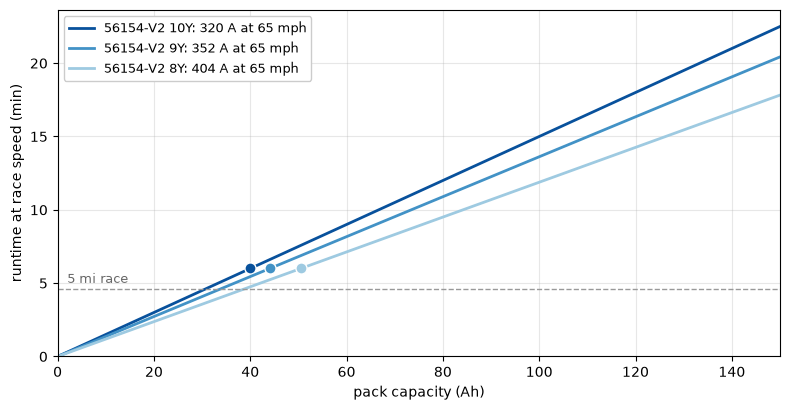

In [10]:
Ah = np.linspace(0, 150, 50)
fig, ax = plt.subplots(figsize=(8, 4.2))
for x, color in zip(PICKS, [DARK, BLUE, "#9ecae1"]):
    r = x["r"]
    ax.plot(Ah, 60 * USABLE * Ah / r["amps"], color=color, lw=2,
            label=f"{x['m']['name'].replace('SSS ', '')}: {r['amps']:.0f} A at {r['mph']:.0f} mph")
    ax.plot(r["C"], r["minutes"], "o", color=color, ms=8, markeredgecolor="white")
ax.axhline(60 * RACE["miles"] / PICKS[0]["r"]["mph"], color="#999999", lw=1, ls="--")
ax.text(2, 60 * RACE["miles"] / PICKS[0]["r"]["mph"] + 0.4, f"{RACE['miles']:g} mi race", fontsize=9, color="#666666")
ax.set_xlabel("pack capacity (Ah)"); ax.set_ylabel("runtime at race speed (min)")
ax.set_xlim(0, Ah[-1]); ax.set_ylim(bottom=0); ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc="upper left", framealpha=1)
plt.tight_layout(); plt.show()

## Not modeled

- Prop curves: `K_Q`, `K_T`, `η_p` are constants, but they change with pitch and boat speed.
- Pack voltage sag under load.
- Getting onto plane (the drag hump around 10 mph). Slow designs are optimistic.
- The sheet's continuous/peak power ratings. Only `I_max`, `v_max` and `max_rpm` are enforced.